In [2]:
import pandas as pd
import matplotlib.pyplot as plt

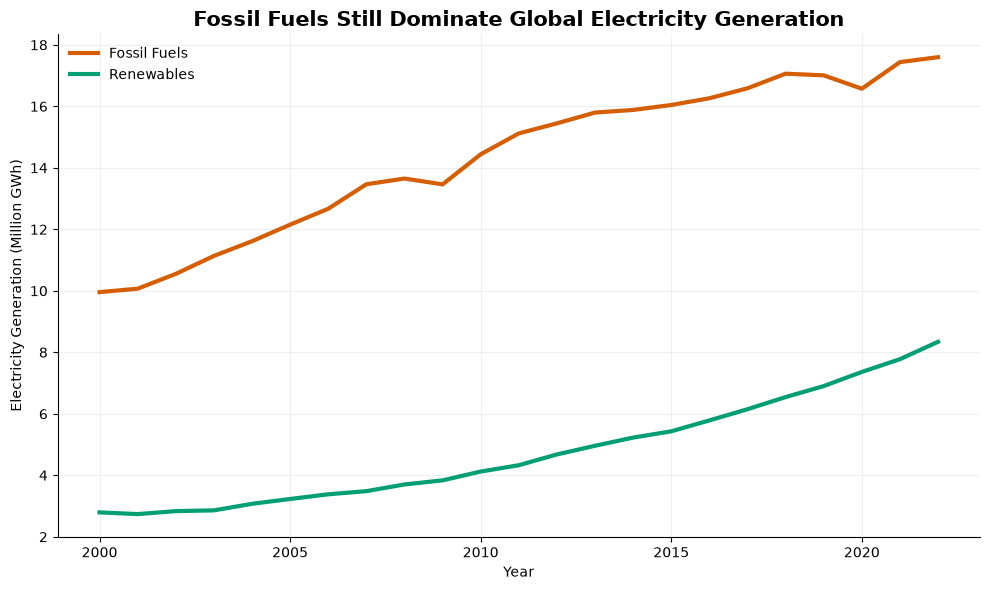

In [9]:
df = pd.read_csv("renewable_energy.csv")

# 2. Select electricity generation data
df = df[
    (df["INDICATOR"] == "Electricity Generation, Gigawatt hours") &
    (df["COUNTRY"].isin(
        ["Africa", "Americas", "Asia", "Europe", "Oceania"]
    ))
].copy()

# 3. Convert year columns into rows
years = [str(year) for year in range(2000, 2023)]

df = df.melt(
    id_vars=["COUNTRY", "ENERGY_SOURCE"],
    value_vars=years,
    var_name="Year",
    value_name="Generation"
)

df["Year"] = df["Year"].astype(int)

# 4. Group energy sources
df["Energy Type"] = df["ENERGY_SOURCE"].apply(
    lambda x: "Fossil Fuels" if x == "Fossil fuels"
    else "Renewables"
)

# 5. Sum electricity generation across continents
global_energy = (
    df.groupby(["Year", "Energy Type"])["Generation"]
    .sum()
    .unstack()
)

# Convert GWh to million GWh
global_energy = global_energy / 1_000_000

# 6. Plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    global_energy.index,
    global_energy["Fossil Fuels"],
    color="#D55E00",
    linewidth=3,
    label="Fossil Fuels"
)

ax.plot(
    global_energy.index,
    global_energy["Renewables"],
    color="#009E73",
    linewidth=3,
    label="Renewables"
)

ax.set_title(
    "Fossil Fuels Still Dominate Global Electricity Generation",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Year")
ax.set_ylabel("Electricity Generation (Million GWh)")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

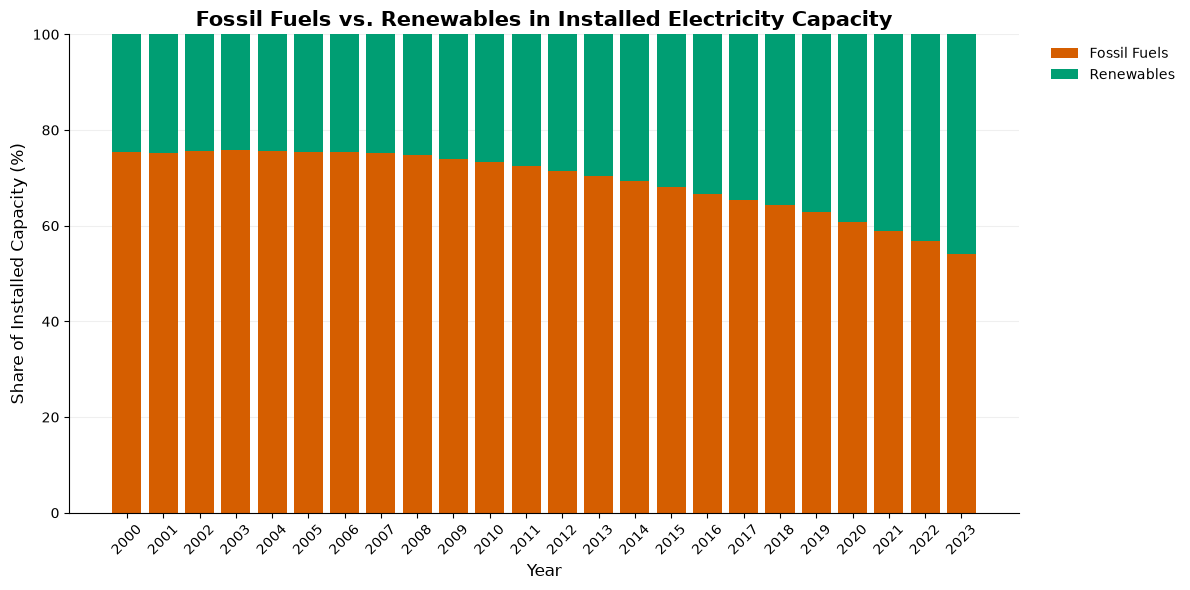

In [10]:
df = pd.read_csv("renewable_energy.csv")
# 2. Select electricity generation data
df = df[
    (df["INDICATOR"] == "Electricity Installed Capacity, Megawatt") &
    (df["COUNTRY"].isin(
        ["Africa", "Americas", "Asia", "Europe", "Oceania"]
    ))
].copy()

# 3. Convert year columns into rows
years = [str(year) for year in range(2000, 2024)]

df = df.melt(
    id_vars=["COUNTRY", "ENERGY_SOURCE"],
    value_vars=years,
    var_name="Year",
    value_name="Generation"
)

df["Year"] = df["Year"].astype(int)

# 4. Group energy sources
df["Energy Type"] = df["ENERGY_SOURCE"].apply(
    lambda x: "Fossil Fuels" if x == "Fossil fuels"
    else "Renewables"
)

# 5. Sum electricity generation across continents
global_energy = (
    df.groupby(["Year", "Energy Type"])["Generation"]
    .sum()
    .unstack()
)

global_energy = global_energy.div(
    global_energy.sum(axis=1), axis=0
) * 100

# 6. Plot stacked bar chart
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    global_energy.index,
    global_energy["Fossil Fuels"],
    color="#D55E00",
    label="Fossil Fuels"
)

ax.bar(
    global_energy.index,
    global_energy["Renewables"],
    bottom=global_energy["Fossil Fuels"],
    color="#009E73",
    label="Renewables"
)

ax.set_title(
    "Fossil Fuels vs. Renewables in Installed Electricity Capacity",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Year",fontsize=12)
ax.set_ylabel("Share of Installed Capacity (%)",fontsize=12,)
ax.set_xticks(global_energy.index)
ax.set_xticklabels(global_energy.index, rotation=45)

ax.set_ylim(0, 100)
ax.legend(
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()